# 0. Engine Fit Diagnostics
- Figure 1: PCIS influence screening (null calibration, masking simulation, real example).
- Figure 2: empirical-Bayes dispersion model (trend, bias, intercept and slope shrinkage).
- Figure S1: individual-fit convergence at low nz (pooling threshold).
- Producers (run once, cache-first): `notebookscripts/EngineDiagnostics/pcis_case_study.py`, `notebookscripts/EngineDiagnostics/low_nz_convergence.py`; outputs in `config.ENGINE_DIAG_DIR`.

In [ ]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import json
import os
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

os.environ["NM_PIPELINE"] = "p0"
sys.path.insert(0, str(Path.cwd().parents[1]))
import MixedEffectsModeling.config as config
from MixedEffectsModeling.core.dispersion_trend import load_trend
from viz_style import apply_style
apply_style()

FIG = config.ENGINE_DIAG_DIR / "Figures"
FIG.mkdir(parents=True, exist_ok=True)
CUT = config.FIT_PARAMS["pcis_cut"]
BLUE, ORANGE, RED = "#2b5c8f", "#e07a5f", "#d62828"

def grid_on(ax):
    ax.grid(True, which="major", color="0.88", lw=0.7)
    ax.set_axisbelow(True)

def panel(ax, s):
    ax.text(-0.12, 1.02, s, transform=ax.transAxes, fontsize=17, fontweight="bold", va="bottom")

LEG = dict(frameon=False, fontsize=11)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Figure 1. PCIS influence screening
- Panel names are printed under the figure. PCIS uses the trend dispersion $\alpha^{\mathrm{trend}}$ (Eq. 13) instead of the gene's own covariate-dependent $\hat\alpha_i(x_j)$; panels c-d show why on the deployed fits, f on simulated data with known outliers.

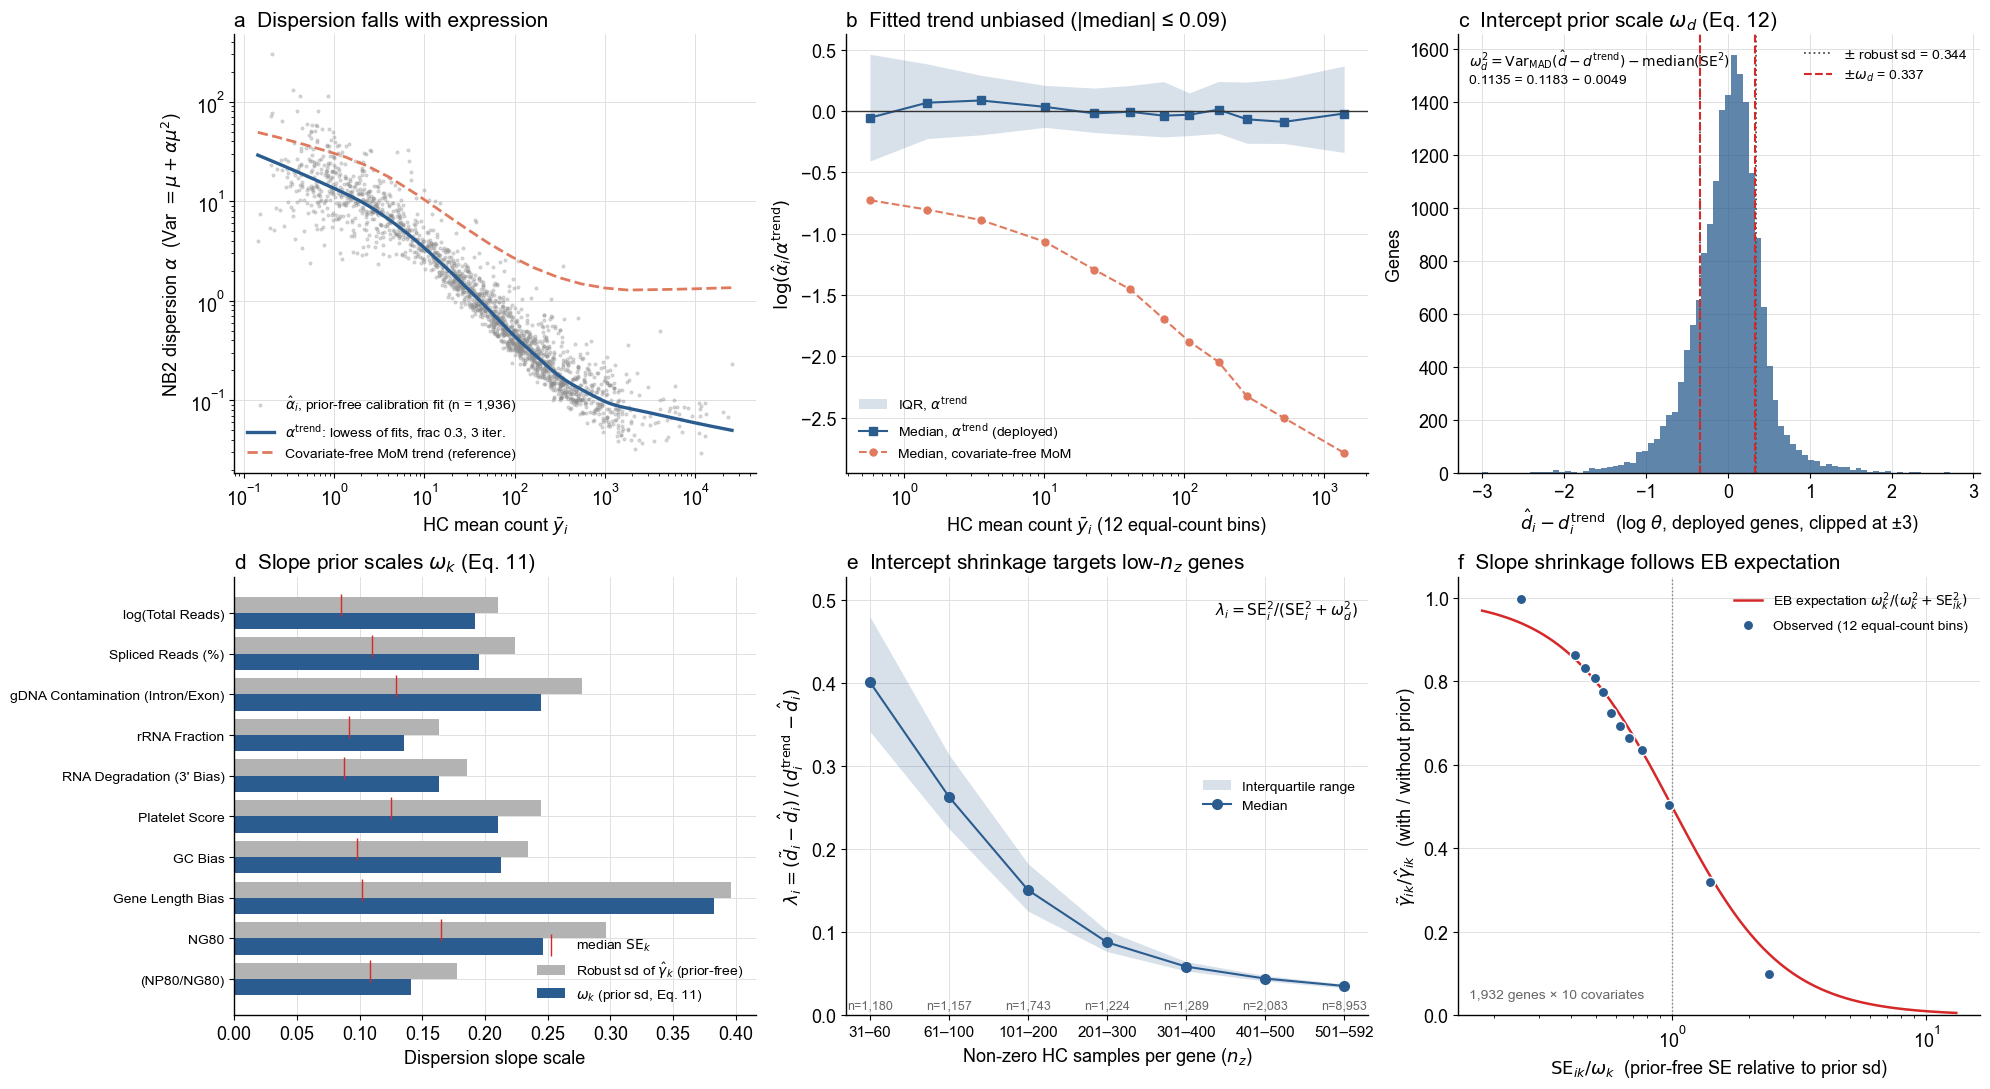

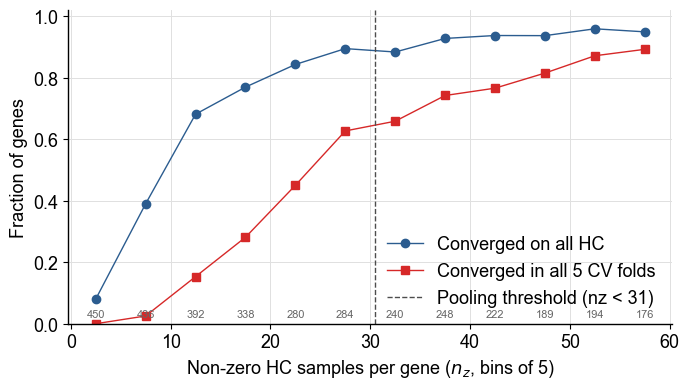

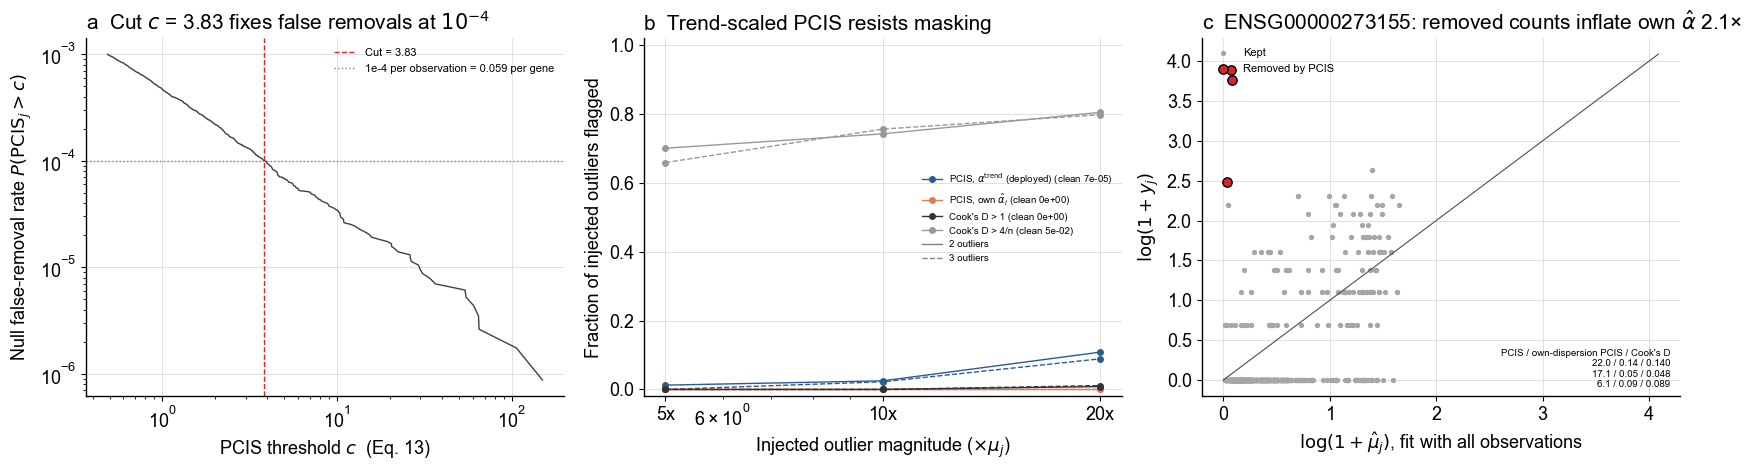

null: 1936 genes x 592 observations; expected false removals per gene at cut = 0.059
clean false-flag rate per observation: {'pcis_trend': '7.0e-05', 'pcis_own': '0.0e+00', 'cooks_1': '0.0e+00', 'cooks_4n': '4.8e-02'}


tpr_pcis_trend  tpr_pcis_own  tpr_cooks_1  tpr_cooks_4n
place      k m                                                          
random     2 5             0.01           0.0         0.00          0.70
             10            0.02           0.0         0.00          0.74
             20            0.11           0.0         0.01          0.80
           3 5             0.00           0.0         0.00          0.66
             10            0.02           0.0         0.00          0.76
             20            0.09           0.0         0.01          0.80
same_batch 2 5             0.00           0.0         0.00          0.72
             10            0.01           0.0         0.00          0.74
             20            0.08           0.0         0.00          0.82
           3 5             0.01           0.0         0.00          0.61
             10            0.02           0.0         0.00          0.72
             20            0.03           0.0         0.00          0.79

real removals reproduced: 1.000 of 699 genes


In [ ]:
null = pd.read_csv(config.PCIS_CAL_DIR / "null_pcis_top50_raw.csv.gz")
null = null[np.isfinite(null.pcis)]
n_obs = int(null.n_obs.iloc[0])
pcis = np.sort(null.pcis.values)[::-1]
rate = np.arange(1, len(pcis) + 1) / (null.groupby(["gene", "rep"]).ngroups * n_obs)
keep = rate <= 1e-3

gcase = pd.read_csv(config.ENGINE_DIAG_DIR / "pcis_cases_gene.csv")
obs = pd.read_csv(config.ENGINE_DIAG_DIR / "pcis_cases_obs.csv.gz").merge(gcase[["gene", "trend_alpha"]], on="gene")
obs["rel_alpha"] = np.log10(obs.alpha_own / obs.trend_alpha)
rem = obs[obs.removed]
full_genes = obs.groupby("gene").size().loc[lambda s: s > 100].index
kept = obs[obs.gene.isin(full_genes) & ~obs.removed]
gcase["inflation"] = gcase.alpha_own_with / gcase.alpha_own_without
ex = gcase[gcase.n_drop >= 2].sort_values("inflation").iloc[-1]
ex_name = ex.symbol if isinstance(ex.symbol, str) and not ex.symbol.startswith("ENSG") else ex.gene.split(".")[0]
o = obs[obs.gene == ex.gene]
r = o[o.removed]

sim = pd.read_csv(config.ENGINE_DIAG_DIR / "pcis_masking_sim.csv")
METH = [("pcis_trend", r"PCIS, $\alpha^{\mathrm{trend}}$ (deployed)", BLUE, "o"), ("pcis_own", r"PCIS, own $\hat{\alpha}_i(x_j)$", ORANGE, "s"),
        ("cooks_1", "Cook's D > 1", "0.15", "^"), ("cooks_4n", "Cook's D > 4/n", "0.6", "D")]
clean = sim[sim.k == 0]
fp_per_fit = {m: clean[f"fp_{m}"].mean() for m, *_ in METH}
det = sim[(sim.k > 0) & (sim.place == "random")].groupby(["mean_hc", "m"])[[f"tpr_{m}" for m, *_ in METH]].mean().reset_index()

fig, axes = plt.subplots(2, 3, figsize=(19, 11))
ax = axes[0, 0]
bins = np.linspace(-3, np.log10(pcis.max()) + 0.1, 70)
ax.hist(np.log10(null.pcis), bins=bins, density=True, color="0.6", alpha=0.8, label="Null (top 50 of 592 per gene)")
ax.hist(np.log10(rem.pcis_trend), bins=bins, density=True, color=RED, alpha=0.6, label=f"Removed in deployed fit (n = {len(rem)})")
ax.axvline(np.log10(CUT), color="0.1", ls="--", lw=1.5, label=f"Cut c = {CUT:.2f}")
ax.set_xlabel(r"$\log_{10}\,\mathrm{PCIS}_j$  (Eq. 13)"); ax.set_ylabel("Density")
ax.legend(**LEG, loc="upper left"); grid_on(ax); panel(ax, "a")

ax = axes[0, 1]
ax.loglog(pcis[keep], rate[keep], color="0.2", lw=1.5)
ax.axvline(CUT, color=RED, ls="--", lw=1.5, label=f"c = {CUT:.2f}")
ax.axhline(1e-4, color="0.4", ls=":", lw=1.5, label=r"$10^{-4}$ per observation" + f" = {1e-4 * n_obs:.3f} per gene")
ax.set_xlabel(r"PCIS threshold $c$"); ax.set_ylabel(r"Null $P(\mathrm{PCIS}_j > c)$")
ax.legend(**LEG); grid_on(ax); panel(ax, "b")

ax = axes[0, 2]
b2 = np.linspace(-1.5, 3, 60)
ax.hist(kept.rel_alpha.clip(-1.5, 3), bins=b2, density=True, color="0.6", alpha=0.8, label=f"Kept observations (n = {len(kept):,})")
ax.hist(rem.rel_alpha.clip(-1.5, 3), bins=b2, density=True, color=RED, alpha=0.6, label=f"Removed observations (n = {len(rem)})")
ax.axvline(0, color="0.1", lw=1)
ax.set_xlabel(r"$\log_{10}\,[\hat{\alpha}_i(x_j)\,/\,\alpha^{\mathrm{trend}}]$  at the observation")
ax.set_ylabel("Density")
ax.legend(**LEG, loc="upper left"); grid_on(ax); panel(ax, "c")

ax = axes[1, 0]
ax.scatter(rem.pcis_trend, rem.pcis_own, s=14, color=ORANGE, alpha=0.7, label=r"PCIS with own $\hat{\alpha}_i(x_j)$")
ax.scatter(rem.pcis_trend, rem.cooks, s=14, color="0.3", alpha=0.6, marker="^", label="Cook's distance")
ax.axvline(CUT, color=RED, ls="--", lw=1.5, label=f"c = {CUT:.2f}")
ax.axhline(CUT, color=RED, ls="--", lw=1.5)
ax.axhline(1, color="0.3", ls=":", lw=1.5, label="Cook's D = 1")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"PCIS with $\alpha^{\mathrm{trend}}$ (deployed)"); ax.set_ylabel("Same observation, alternative score")
ax.legend(**LEG, loc="lower right"); grid_on(ax); panel(ax, "d")

ax = axes[1, 1]
ax.scatter(np.log1p(o.mu), np.log1p(o.y), s=10, color="0.6", label="Kept")
ax.scatter(np.log1p(r.mu), np.log1p(r.y), s=60, color=RED, edgecolor="black", zorder=3, label="Removed by PCIS")
lim = [0, max(np.log1p(o.y).max(), np.log1p(o.mu).max()) * 1.05]
ax.plot(lim, lim, color="0.3", lw=1)
ax.set_xlabel(r"$\log(1+\hat{\mu}_j)$, fit with all observations"); ax.set_ylabel(r"$\log(1+y_j)$")
ax.text(0.98, 0.03, f"{ex_name}\nown " + r"$\hat{\alpha}$" + f" {ex.alpha_own_with:.2f} → {ex.alpha_own_without:.2f} after removal\n"
        + r"$\alpha^{\mathrm{trend}}$" + f" = {ex.trend_alpha:.2f}", transform=ax.transAxes, ha="right", va="bottom", fontsize=11)
ax.legend(**LEG, loc="upper left"); grid_on(ax); panel(ax, "e")

ax = axes[1, 2]
for m, lab, c, mk in METH:
    for mag, ls in [(20, "-"), (10, "--")]:
        s = det[det.m == mag]
        ax.plot(s.mean_hc, s[f"tpr_{m}"], ls=ls, marker=mk, ms=7, color=c, lw=1.5,
                label=f"{lab} ({fp_per_fit[m]:.2f} false/fit)" if mag == 20 else None)
ax.plot([], [], color="0.4", ls="-", label="20x outliers"); ax.plot([], [], color="0.4", ls="--", label="10x outliers")
ax.set_xscale("log"); ax.set_ylim(-0.03, 1.03)
ax.set_xlabel(r"Simulated gene HC mean count $\bar{y}_i$"); ax.set_ylabel("Fraction of 2-3 injected outliers flagged")
ax.legend(frameon=False, fontsize=10, loc="center left"); grid_on(ax); panel(ax, "f")
plt.tight_layout()
plt.savefig(FIG / "fig1_pcis.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figure 1. PCIS influence screening")
print("  a  Null PCIS distribution (parametric bootstrap) and PCIS of observations removed in the deployed fit")
print("  b  Null false-removal rate vs threshold; cut at 1e-4 per observation")
print("  c  Gene's own covariate-dependent dispersion relative to the trend, at kept vs removed observations")
print("  d  Removed observations re-scored with own dispersion (PCIS) and with Cook's distance")
print(f"  e  Example gene with removed observations: {ex_name}")
print("  f  Simulation: detection of 2-3 injected outliers by gene expression level (random positions)")
print(f"\nremoved observations {len(rem)}: above cut with own dispersion {(rem.pcis_own > CUT).sum()}, Cook's D > 1 {(rem.cooks > 1).sum()}, Cook's D > 4/n {(rem.cooks > 4 / n_obs).mean():.2f}")
print(f"own/trend dispersion at observation, median fold: removed {10 ** rem.rel_alpha.median():.1f}x, kept {10 ** kept.rel_alpha.median():.1f}x")
print("clean false flags per fit:", {k: round(v, 3) for k, v in fp_per_fit.items()})
display(sim[sim.k > 0].groupby(["mean_hc", "place", "m"])[[f"tpr_{m}" for m, *_ in METH]].mean().round(2))

## Figure 2. Empirical-Bayes dispersion model
Notation follows the Methods: NB2 $\mathrm{Var}(y)=\mu+\alpha\mu^2$, $\theta = 1/\alpha$, dispersion intercept $d_i = \log\theta_i$, slopes $\gamma_{ik}$. Supersedes the training-time panel `EngineState/Figures/dispersion_trend.png`.
- **a** Prior-free calibration fits (1,936 genes) and the lowess trend $\alpha^{\mathrm{trend}}$ that centres the intercept prior (Eq. 12) and scales the PCIS residual (Eq. 13). Dashed: covariate-free method-of-moments trend on raw HC counts (reference).
- **b** Bias of each trend against the conditional fits by expression bin: the fitted trend stays near 0, the covariate-free MoM trend overstates dispersion increasingly with expression, which is why the trend is built from covariate-conditional fits.
- **c** Intercept prior scale (Eq. 12): $\omega_d^2$ = robust (MAD) variance of $\hat d_i - d_i^{\mathrm{trend}}$ over deployed genes minus the median $\mathrm{SE}_i^2$.
- **d** Slope prior scales (Eq. 11): per covariate, the robust spread of prior-free slopes $\hat\gamma_{k}$ splits into estimation noise (median $\mathrm{SE}_k$) and true between-gene spread $\omega_k$.
- **e** Eq. 12 moves $\hat d_i$ toward $d_i^{\mathrm{trend}}$ by $\lambda_i = \mathrm{SE}_i^2/(\mathrm{SE}_i^2+\omega_d^2)$; the move is large only for genes with few non-zero samples.
- **f** Slopes fitted with the prior vs the same genes without it, against the normal-normal expectation $\omega_k^2/(\omega_k^2+\mathrm{SE}_{ik}^2)$ (a check, not an identity: the deployed slopes come from a joint glmmTMB fit).

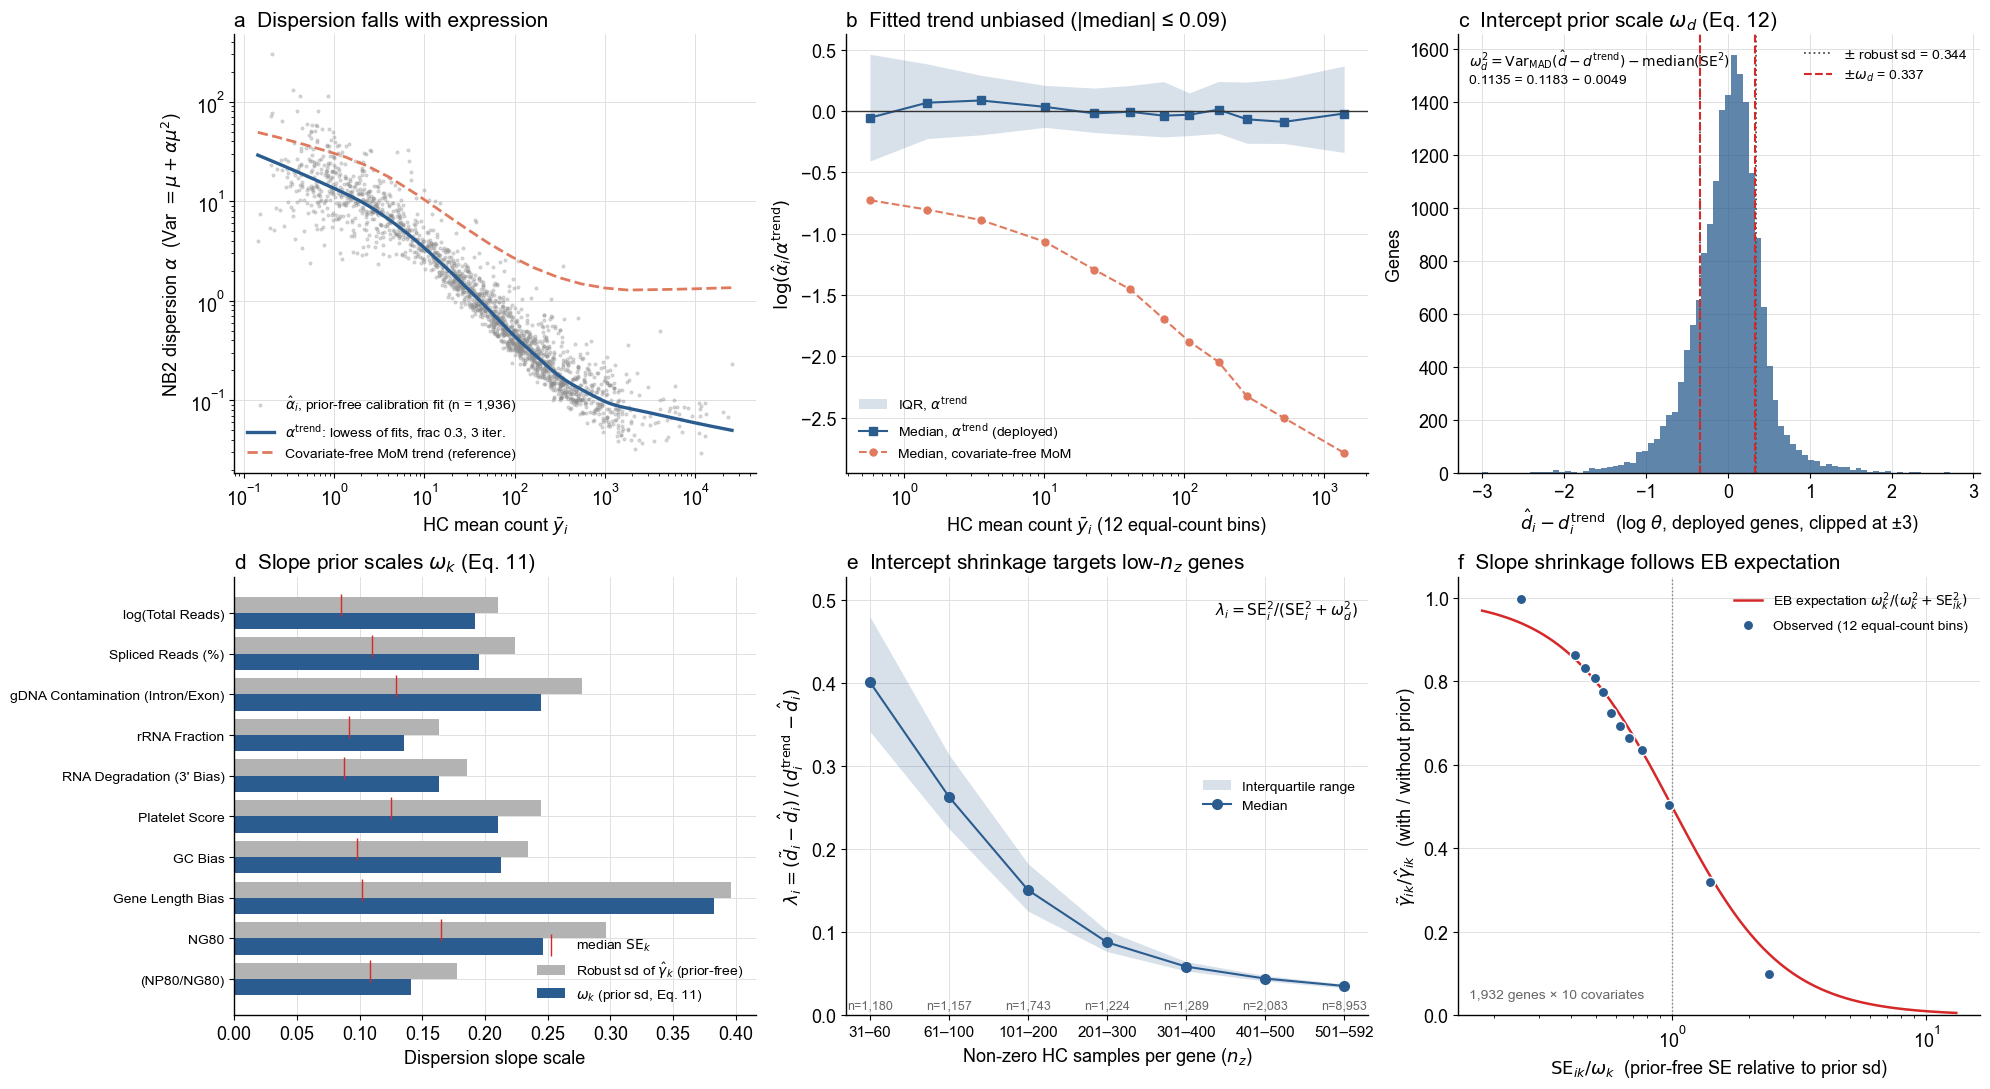

b: fitted trend |median| max 0.087; MoM trend median range -2.79 to -0.73
c: omega_d^2 0.1135 vs MAD var 0.1183 - median SE^2 0.0049 = 0.1135


,omega_k,robust_sd_prior_free,median_SE
log(Total Reads),0.192,0.210,0.085
Spliced Reads (%),0.195,0.224,0.110
gDNA Contamination (Intron/Exon),0.245,0.277,0.129
rRNA Fraction,0.135,0.163,0.091
RNA Degradation (3' Bias),0.163,0.185,0.087
Platelet Score,0.210,0.245,0.125
GC Bias,0.213,0.234,0.098
Gene Length Bias,0.383,0.396,0.102
NG80,0.246,0.296,0.165
(NP80/NG80),0.141,0.178,0.109


,lambda_median,lambda_q25,lambda_q75,SE_median,n
nz,,,,,
"(30, 60]",0.401,0.342,0.480,0.276,1180
"(60, 100]",0.263,0.225,0.314,0.201,1157
"(100, 200]",0.151,0.125,0.183,0.142,1743
"(200, 300]",0.088,0.077,0.102,0.105,1224
"(300, 400]",0.059,0.053,0.065,0.084,1289
"(400, 500]",0.044,0.041,0.048,0.072,2083
"(500, 592]",0.035,0.033,0.038,0.064,8953


,x,ratio,n
x,,,
"(0.178, 0.387]",0.254,0.997,1610.0
"(0.387, 0.436]",0.415,0.863,1610.0
"(0.436, 0.476]",0.455,0.831,1610.0
"(0.476, 0.516]",0.497,0.807,1610.0
"(0.516, 0.554]",0.534,0.774,1610.0
"(0.554, 0.601]",0.577,0.725,1610.0
"(0.601, 0.65]",0.624,0.692,1610.0
"(0.65, 0.714]",0.679,0.664,1610.0
"(0.714, 0.844]",0.764,0.635,1610.0


In [ ]:
from MixedEffectsModeling.core.dispersion_trend import build_trend, save_trend

CAL_MEAN = config.ENGINE_DIAG_DIR / "calib_gene_mean.csv"
MOM_TREND = config.ENGINE_DIAG_DIR / "mom_trend.json"
calib = pd.read_csv(config.ENGINE_DIR / "calib_fits.csv")
if not (CAL_MEAN.is_file() and MOM_TREND.is_file()):
    import scanpy as sc
    hc = pd.read_csv(config.ZSCORES_DIR / "hc_meta.csv")["sample"].values
    ad = sc.read_h5ad(config.H5AD_PATH, backed="r")
    assert np.isin(hc, ad.obs_names).all()
    pc = ad.var_names[(ad.var["GeneType"] == "protein_coding").values]
    Y = ad[hc, pc].to_memory().X
    Y = np.round(Y.toarray() if hasattr(Y, "toarray") else np.asarray(Y))
    pd.Series(Y[:, pc.get_indexer(calib.gene.values)].mean(0), index=pd.Index(calib.gene.values, name="gene"),
              name="mean_hc").to_frame().to_csv(CAL_MEAN)
    save_trend(build_trend(Y), MOM_TREND)
    del Y
cmean = pd.read_csv(CAL_MEAN, index_col="gene")["mean_hc"]
trend_cfg = json.load(open(config.ENGINE_DIR / "dispersion_trend.json"))
alpha_of = load_trend(config.ENGINE_DIR / "dispersion_trend.json")
mom_of = load_trend(MOM_TREND)

cal = calib[calib.ok.astype(bool)].copy()
cal["mean_hc"] = cmean.reindex(cal.gene).values
cal["alpha_fit"] = np.exp(-cal.disp_coef_0)
cal["resid"] = np.log(cal.alpha_fit) - np.log([alpha_of(m) for m in cal.mean_hc])
cal["resid_mom"] = np.log(cal.alpha_fit) - np.log([mom_of(m) for m in cal.mean_hc])
tb = cal.groupby(pd.qcut(np.log(cal.mean_hc), 12), observed=True).agg(
    mu=("mean_hc", "median"), med=("resid", "median"), med_mom=("resid_mom", "median"),
    q25=("resid", lambda s: s.quantile(0.25)), q75=("resid", lambda s: s.quantile(0.75)))

def mad_var(v):
    v = np.asarray(v, float); v = v[np.isfinite(v)]
    return (1.4826 * np.median(np.abs(v - np.median(v)))) ** 2

genes = pickle.load(open(config.ENGINE_DIR / "genes.pkl", "rb"))
omega_d = json.load(open(config.ENGINE_DIR / "eb_meta.json"))["disp_tau_d"]
prior = json.load(open(config.ENGINE_DIR / "disp_prior.json"))
covs, omega = prior["covariates"], np.asarray(prior["tau_slope"])
rec = pd.DataFrame([dict(nz=r.nz, d_hat=r.log_theta_raw, d_tilde=r.log_theta_eb, d_trend=-np.log(r.trend_alpha), se=r.disp_se[0])
                    for r in genes.values() if r.ok and r.route == "model" and r.log_theta_eb is not None])
dev = rec.d_hat - rec.d_trend
var_tot, se2_med = mad_var(dev), np.nanmedian(rec.se ** 2)
rec = rec[np.abs(dev) > 1e-6].assign(lam=lambda d: (d.d_tilde - d.d_hat) / (d.d_trend - d.d_hat))
nzb = rec.groupby(pd.cut(rec.nz, [30, 60, 100, 200, 300, 400, 500, 592]), observed=True)

full = cal[cal.stage == "nbi_full_eb"].set_index("gene")
common = [g for g in full.index if g in genes and genes[g].ok and genes[g].stage == "nbi_full_eb"]
K = len(covs)
g_hat = full.loc[common, [f"disp_coef_{k}" for k in range(1, K + 1)]].to_numpy(float)
se_k = full.loc[common, [f"disp_se_{k}" for k in range(1, K + 1)]].to_numpy(float)
g_tilde = np.array([genes[g].disp_coef[1:K + 1] for g in common], dtype=float)
cal_full = full[full.ok.astype(bool)]
spread_k = np.sqrt([mad_var(cal_full[f"disp_coef_{k}"]) for k in range(1, K + 1)])
se_med_k = np.sqrt([np.nanmedian(cal_full[f"disp_se_{k}"] ** 2) for k in range(1, K + 1)])
sl = pd.DataFrame({"x": (se_k / omega).ravel(), "g_hat": g_hat.ravel(), "g_tilde": g_tilde.ravel()}).dropna()
sl = sl[np.isfinite(sl.x) & (sl.x > 0)]
sb = sl.groupby(pd.qcut(sl.x, 12), observed=True).apply(lambda s: pd.Series({
    "x": s.x.median(), "ratio": (s.g_tilde * s.g_hat).sum() / (s.g_hat ** 2).sum(), "n": len(s)}))

fig, axes = plt.subplots(2, 3, figsize=(19, 11))
ax = axes[0, 0]
panel(ax, "a")
xg = np.geomspace(cal.mean_hc.min(), cal.mean_hc.max(), 300)
ax.scatter(cal.mean_hc, cal.alpha_fit, s=4, alpha=0.3, color="0.55", rasterized=True,
           label=r"$\hat{\alpha}_i$, prior-free calibration fit" + f" (n = {len(cal):,})")
ax.plot(xg, [alpha_of(m) for m in xg], color=BLUE, lw=2.4,
        label=r"$\alpha^{\mathrm{trend}}$: lowess of fits, frac " + f"{trend_cfg['lowess_frac']}, {trend_cfg['lowess_it']} iter.")
ax.plot(xg, [mom_of(m) for m in xg], color=ORANGE, lw=2, ls="--", label="Covariate-free MoM trend (reference)")
ax.set_xscale("log"); ax.set_yscale("log"); grid_on(ax)
ax.set_xlabel(r"HC mean count $\bar{y}_i$")
ax.set_ylabel(r"NB2 dispersion $\alpha$  (Var $= \mu + \alpha\mu^2$)")
ax.legend(frameon=False, fontsize=11, loc="lower left")

ax = axes[0, 1]
panel(ax, "b")
ax.fill_between(tb.mu, tb.q25, tb.q75, color=BLUE, alpha=0.18, lw=0, label=r"IQR, $\alpha^{\mathrm{trend}}$")
ax.plot(tb.mu, tb.med, "s-", color=BLUE, ms=6, lw=1.5, label=r"Median, $\alpha^{\mathrm{trend}}$ (deployed)")
ax.plot(tb.mu, tb.med_mom, "o--", color=ORANGE, ms=5, lw=1.5, label="Median, covariate-free MoM")
ax.axhline(0, color="0.2", lw=1)
ax.set_xscale("log"); grid_on(ax)
ax.set_xlabel(r"HC mean count $\bar{y}_i$ (12 equal-count bins)")
ax.set_ylabel(r"$\log(\hat{\alpha}_i / \alpha^{\mathrm{trend}})$")
ax.legend(frameon=False, fontsize=11, loc="lower left")

ax = axes[0, 2]
panel(ax, "c")
ax.hist(dev.clip(-3, 3), bins=80, color=BLUE, alpha=0.75)
for s in (-1, 1):
    ax.axvline(s * np.sqrt(var_tot), color="0.3", ls=":", lw=1.3, label=r"$\pm$ robust sd" + f" = {np.sqrt(var_tot):.3f}" if s == 1 else None)
    ax.axvline(s * omega_d, color=RED, ls="--", lw=1.5, label=r"$\pm\omega_d$" + f" = {omega_d:.3f}" if s == 1 else None)
grid_on(ax)
ax.set_xlabel(r"$\hat{d}_i - d_i^{\mathrm{trend}}$  (log $\theta$, deployed genes, clipped at ±3)")
ax.set_ylabel("Genes")
ax.text(0.02, 0.97, r"$\omega_d^2 = \mathrm{Var}_{\mathrm{MAD}}(\hat{d}-d^{\mathrm{trend}}) - \mathrm{median}(\mathrm{SE}^2)$" + "\n"
        + f"{omega_d ** 2:.4f} = {var_tot:.4f} − {se2_med:.4f}", transform=ax.transAxes, va="top", fontsize=10)
ax.legend(frameon=False, fontsize=11, loc="upper right")

ax = axes[1, 0]
panel(ax, "d")
y = np.arange(K)
ax.barh(y - 0.2, spread_k, height=0.4, color="0.7", label=r"Robust sd of $\hat{\gamma}_k$ (prior-free)")
ax.barh(y + 0.2, omega, height=0.4, color=BLUE, label=r"$\omega_k$ (prior sd, Eq. 11)")
ax.scatter(se_med_k, y - 0.2, marker="|", s=250, color=RED, zorder=3, label=r"median $\mathrm{SE}_k$")
ax.set_yticks(y); ax.set_yticklabels(covs, fontsize=10); ax.invert_yaxis(); grid_on(ax)
ax.set_xlabel("Dispersion slope scale")
ax.legend(frameon=False, fontsize=11, loc="lower right")

ax = axes[1, 1]
panel(ax, "e")
x = np.arange(nzb.ngroups)
med, q25, q75 = nzb.lam.median(), nzb.lam.quantile(0.25), nzb.lam.quantile(0.75)
ax.fill_between(x, q25, q75, color=BLUE, alpha=0.18, lw=0, label="Interquartile range")
ax.plot(x, med, "o-", color=BLUE, ms=7, lw=1.5, label="Median")
for xi, n in zip(x, nzb.size()):
    ax.text(xi, 0.005, f"n={n:,}", ha="center", va="bottom", fontsize=10, color="0.4")
ax.set_xticks(x); ax.set_xticklabels([f"{int(i.left) + 1}–{int(i.right)}" for i in med.index], fontsize=11)
ax.set_ylim(0, max(0.5, q75.max() * 1.1)); grid_on(ax)
ax.set_xlabel(r"Non-zero HC samples per gene ($n_z$)")
ax.set_ylabel(r"$\lambda_i = (\tilde{d}_i - \hat{d}_i)\,/\,(d_i^{\mathrm{trend}} - \hat{d}_i)$")
ax.text(0.98, 0.95, r"$\lambda_i = \mathrm{SE}_i^2 / (\mathrm{SE}_i^2 + \omega_d^2)$", transform=ax.transAxes, ha="right", va="top", fontsize=11)
ax.legend(frameon=False, fontsize=11, loc="center right")

ax = axes[1, 2]
panel(ax, "f")
xs = np.geomspace(sl.x.min(), sl.x.max(), 300)
ax.plot(xs, 1 / (1 + xs ** 2), color=RED, lw=1.8, label=r"EB expectation $\omega_k^2 / (\omega_k^2 + \mathrm{SE}_{ik}^2)$")
ax.scatter(sb.x, sb.ratio, s=55, color=BLUE, edgecolor="white", zorder=3, label="Observed (12 equal-count bins)")
ax.axvline(1, color="0.5", ls=":", lw=1)
ax.set_xscale("log"); ax.set_ylim(0, 1.05); grid_on(ax)
ax.set_xlabel(r"$\mathrm{SE}_{ik} / \omega_k$  (prior-free SE relative to prior sd)")
ax.set_ylabel(r"$\tilde{\gamma}_{ik} / \hat{\gamma}_{ik}$  (with / without prior)")
ax.text(0.02, 0.04, f"{len(common):,} genes × {K} covariates", transform=ax.transAxes, fontsize=10, color="0.4")
ax.legend(frameon=False, fontsize=11, loc="upper right")
plt.tight_layout()
plt.savefig(FIG / "fig2_dispersion_eb.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figure 2. Empirical-Bayes dispersion model")
print("  a  Mean-dispersion relationship: prior-free calibration fits, lowess trend, covariate-free MoM reference")
print("  b  Trend bias by expression bin (fitted trend vs covariate-free MoM)")
print("  c  Intercept prior scale omega_d: deviation of d_hat from the trend, Eq. 12")
print("  d  Slope prior scales omega_k per covariate: total spread vs estimation noise, Eq. 11")
print("  e  Intercept shrink fraction lambda_i by non-zero HC samples n_z")
print("  f  Slope shrinkage with vs without prior against the EB expectation")

print(f"b: fitted trend |median| max {tb.med.abs().max():.3f}; MoM trend median range {tb.med_mom.min():+.2f} to {tb.med_mom.max():+.2f}")
print(f"c: omega_d^2 {omega_d ** 2:.4f} vs MAD var {var_tot:.4f} - median SE^2 {se2_med:.4f} = {var_tot - se2_med:.4f}")
display(pd.DataFrame({"omega_k": omega, "robust_sd_prior_free": spread_k, "median_SE": se_med_k}, index=covs).round(3))
display(pd.DataFrame({"lambda_median": med, "lambda_q25": q25, "lambda_q75": q75, "SE_median": nzb.se.median(), "n": nzb.size()}).round(3))
display(sb.round(3))

## Figure S1. Individual-fit convergence at low nz
- Every gene with nz 1-60 refitted through the individual cascade on all HC and on the 5 CV training folds; left of the line = pooled GLM in the deployed engine.

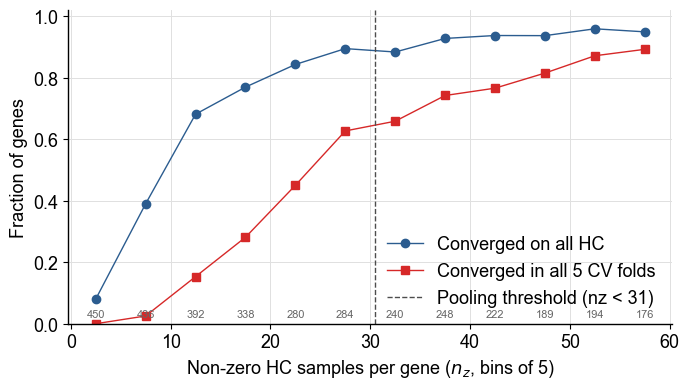

            n  full_ok   all5
nz_bin                       
(0, 5]    450    0.080  0.000
(5, 10]   436    0.390  0.025
(10, 15]  392    0.681  0.153
(15, 20]  338    0.769  0.281
(20, 25]  280    0.843  0.450
(25, 30]  284    0.894  0.627
(30, 35]  240    0.883  0.658
(35, 40]  248    0.927  0.742
(40, 45]  222    0.937  0.766
(45, 50]  189    0.937  0.815
(50, 55]  194    0.959  0.871
(55, 60]  176    0.949  0.892
nbi_intercept_eb_reject_reason
not_converged_or_explosion_or_tau2_bound    1046


In [ ]:
conv = pd.read_csv(config.ENGINE_DIAG_DIR / "low_nz_convergence.csv", index_col="gene")
edges = np.arange(0, 61, 5)
conv["nz_bin"] = pd.cut(conv.nz, edges)
by = conv.groupby("nz_bin", observed=True).agg(
    n=("nz", "size"), full_ok=("full_ok", "mean"), all5=("n_fold_ok", lambda s: (s == 5).mean()))
x = (edges[:-1] + edges[1:]) / 2
x = x[: len(by)]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, by.full_ok, marker="o", color="#2b5c8f", label="Converged on all HC")
ax.plot(x, by.all5, marker="s", color="#d62828", label="Converged in all 5 CV folds")
ax.axvline(config.NZ_A_MAX - 0.5, color="0.3", ls="--", label=r"Pooling threshold ($n_z$ < " + f"{config.NZ_A_MAX})")
for xi, n in zip(x, by.n):
    ax.text(xi, 1.035, f"{n}", ha="center", fontsize=10, color="0.4", transform=ax.get_xaxis_transform())
ax.set_ylim(0, 1.02)
grid_on(ax)
ax.set_xlabel(r"Non-zero HC samples per gene ($n_z$, bins of 5)")
ax.set_ylabel("Fraction of genes")
ax.legend(**LEG, loc="lower right")
ax.text(1.0, 1.08, "genes per bin", transform=ax.transAxes, ha="right", fontsize=10, color="0.4")
plt.tight_layout()
plt.savefig(FIG / "figS1_low_nz_convergence.png", dpi=300, bbox_inches="tight")
plt.show()
print("Figure S1. Individual-fit convergence by non-zero HC samples n_z (all HC and 5 CV folds); left of the line = pooled GLM")
print(by.round(3).to_string())
print(conv.loc[~conv.full_ok, "nbi_intercept_eb_reject_reason"].fillna("(blank)").value_counts().to_string())